In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())
print("\nDataset Information:")
df.info()

Dataset Shape: (7043, 21)

Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null

In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nChurn Distribution:")
print(df["Churn"].value_counts())

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate Rows:
0

Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [5]:
# Remove duplicate rows
df = df.drop_duplicates()

# Convert TotalCharges into numeric values
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Check missing values again
print("Missing values after conversion:")
print(df.isnull().sum())

# Display dataset information
print("\nDataset Shape:", df.shape)

Missing values after conversion:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Dataset Shape: (7043, 21)


In [6]:
# Check missing values in TotalCharges
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

# Fill missing values with the median
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

# Check again
print("\nMissing values after filling:")
print(df.isnull().sum().sum())

print("\nFinal Dataset Shape:", df.shape)

Missing TotalCharges: 11

Missing values after filling:
0

Final Dataset Shape: (7043, 21)


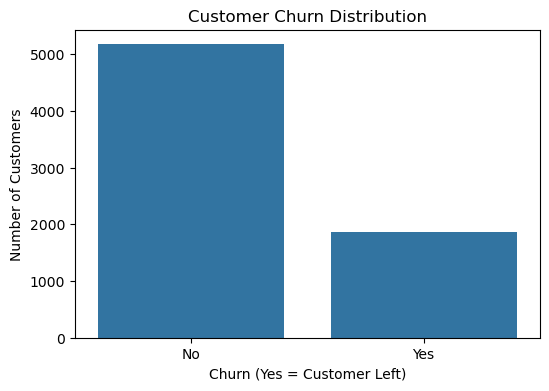

In [7]:
# Visualize customer churn

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (Yes = Customer Left)")
plt.ylabel("Number of Customers")

plt.show()

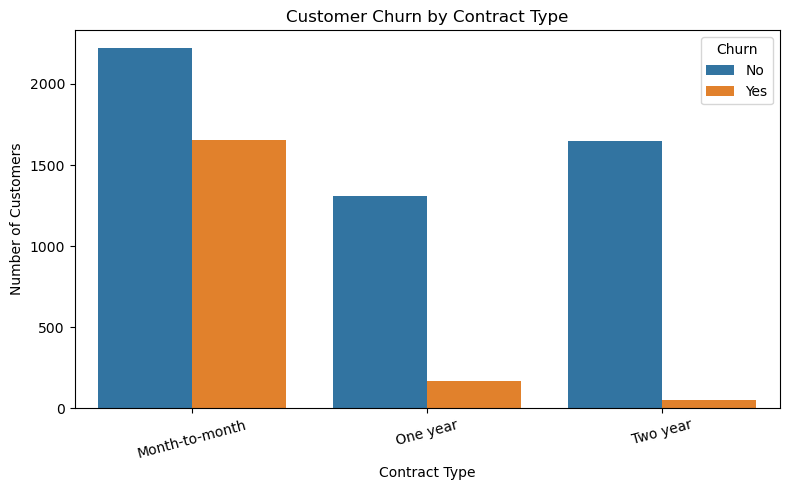

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [9]:
# Remove customer ID because it is not useful for prediction
df = df.drop(columns=["customerID"])

# Convert the target column into numbers
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

# Separate input features and target
X = df.drop(columns=["Churn"])
y = df["Churn"]

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Values:")
print(y.value_counts())

Input Features Shape: (7043, 19)
Target Shape: (7043,)

Target Values:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [10]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (5634, 19)
Testing Data: (1409, 19)
Training Target: (5634,)
Testing Target: (1409,)


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X.select_dtypes(include=["object"]).columns

# Preprocess numerical and categorical data
preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

# Create the machine-learning pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

# Train the model
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Make predictions
y_pred = model.predict(X_test)

# Calculate evaluation metrics
print("Model Evaluation Results")
print("------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))

Model Evaluation Results
------------------------
Accuracy: 0.7381
Precision: 0.5043
Recall: 0.7834
F1 Score: 0.6136

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.90      0.72      0.80      1035
       Churn       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



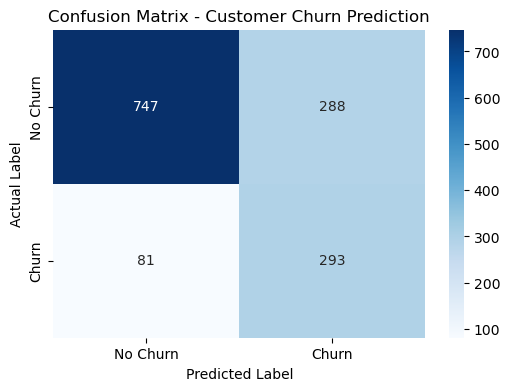

In [13]:
# Create the confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Confusion Matrix - Customer Churn Prediction")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create the Random Forest model
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Compare Logistic Regression and Random Forest
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, rf_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, rf_pred, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, rf_pred, zero_division=0)
    ]
})

print("Model Performance Comparison:")
display(results.round(3))

Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.738,0.504,0.783,0.614
1,Random Forest,0.784,0.623,0.473,0.538


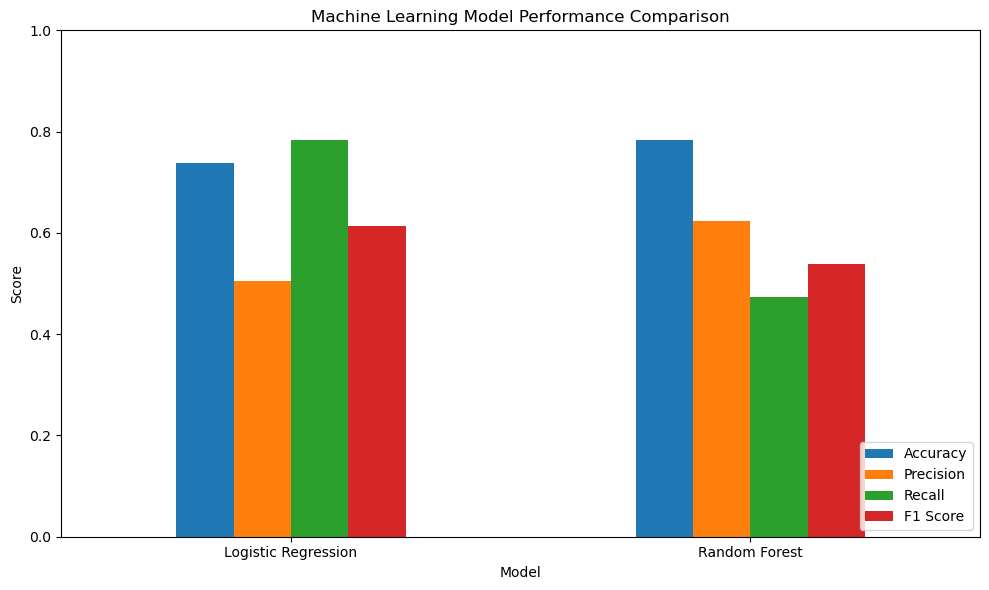

In [16]:
# Plot model performance comparison

results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [17]:
# Identify the best model based on F1 Score

best_model_name = results.loc[results["F1 Score"].idxmax(), "Model"]

print("Best Model:", best_model_name)

print("\nModel Performance Summary:")
print(results.round(3).to_string(index=False))

Best Model: Logistic Regression

Model Performance Summary:
              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression     0.738      0.504   0.783     0.614
      Random Forest     0.784      0.623   0.473     0.538


In [18]:
# Save model comparison results
results.to_csv("model_comparison_results.csv", index=False)

# Save predictions and actual values
prediction_results = pd.DataFrame({
    "Actual_Churn": y_test.values,
    "Logistic_Regression_Prediction": y_pred,
    "Random_Forest_Prediction": rf_pred
})

prediction_results.to_csv("customer_churn_predictions.csv", index=False)

print("Files saved successfully!")
print("1. model_comparison_results.csv")
print("2. customer_churn_predictions.csv")

Files saved successfully!
1. model_comparison_results.csv
2. customer_churn_predictions.csv


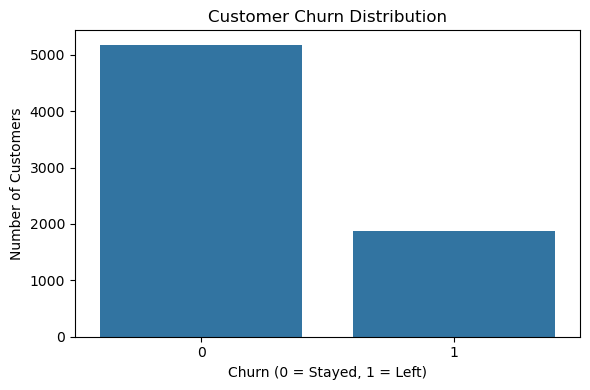

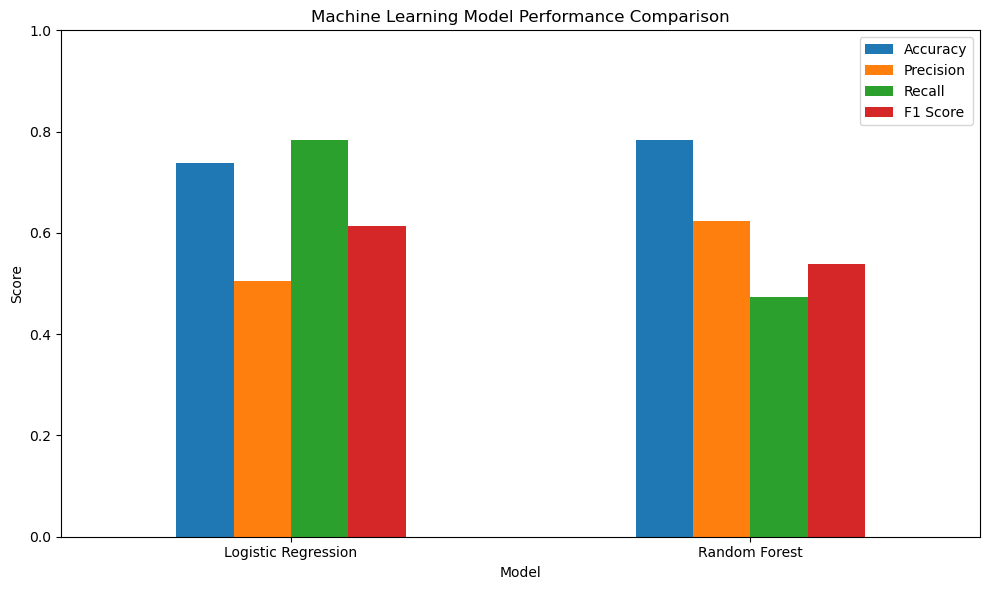

Both graphs saved successfully!


In [19]:
# Save customer churn distribution graph
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = Stayed, 1 = Left)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("customer_churn_distribution.png", dpi=300)
plt.show()

# Save model comparison graph
results.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar", figsize=(10, 6)
)
plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("model_performance_comparison.png", dpi=300)
plt.show()

print("Both graphs saved successfully!")

## Conclusion

This project developed a machine learning approach to predict customer churn using the IBM Telco Customer Churn dataset. The dataset was cleaned and prepared for analysis, and exploratory data visualizations were created to understand customer churn patterns.

Two classification algorithms, Logistic Regression and Random Forest, were trained and evaluated using accuracy, precision, recall, and F1 score. Their performance was compared to identify the model that performed best on the test dataset.

The findings can help businesses identify customers who may leave and develop targeted customer retention strategies. However, predictions are not guaranteed to be correct, and model performance may vary with different datasets.

Future improvements could include hyperparameter tuning, cross-validation, and testing additional machine learning algorithms.